In [47]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [48]:
#db connection

base_parquet_dir = "../data/interim/jobposts_base.parquet"

con = duckdb.connect()
con.read_parquet(base_parquet_dir).create_view("jobposts");

In [49]:
jobposts = con.sql(""" 
    select *
    from jobposts
""").df()

display(jobposts.head())

,RowNumber,Jobpost_RawTitle,Jobpost_PreferredGender,Jobpost_ProvinceFa,Jobpost_ProvinceEn,Jobpost_WorkTypeFa,Jobpost_WorkTypeEn,Jobpost_SalaryCanBeShown,Jobpost_MinSalary,Jobpost_MaxSalary,...,Company_ActivityTypeFa,Company_ActivityTypeEn,Company_IndustryFa,Company_IndustryEn,date,year,month,jalali_year,jalali_month,jalali_season
0,1,مهندس مکانیک,تفاوتی ندارد,تهران,Tehran,پاره وقت,Part Time,False,NaN,NaN,...,شرکت ایرانی دارای مشتریان داخلی,Iranian company dealing only with Iranian enti...,"ساختمان / مصالح و تجهیزات ساختمانی,تولیدی / صنعتی","Construction / Building Materials & Equipment,...",2022-04-01,2022,4,1401,1,Spring
1,2,طراح و گرافیست,تفاوتی ندارد,تهران,Tehran,تمام وقت,Full Time,False,NaN,NaN,...,شرکت ایرانی دارای مشتریان داخلی و خارجی,Iranian company dealing with Iranian and forei...,طراحی / گرافیک / هنر,Design / Arts,2023-03-01,2023,3,1401,12,Winter
2,3,برنامه نویس full-stack,تفاوتی ندارد,خراسان رضوی,Khorasan Razavi,تمام وقت,Full Time,False,NaN,NaN,...,شرکت ایرانی دارای مشتریان داخلی و خارجی,Iranian company dealing with Iranian and forei...,"اینترنت / تجارت الکترونیک / خدمات آنلاین,شرکت ...",Internet Provider / E-commerce / Online Servic...,2022-04-01,2022,4,1401,1,Spring
3,4,بازاریاب - خانم,فقط خانم,البرز,Alborz,تمام وقت,Full Time,False,NaN,NaN,...,شرکت ایرانی دارای مشتریان داخلی,Iranian company dealing only with Iranian enti...,"اینترنت / تجارت الکترونیک / خدمات آنلاین,خرده ...",Internet Provider / E-commerce / Online Servic...,2023-12-01,2023,12,1402,9,Autumn
4,5,برنامه نویس React Native,تفاوتی ندارد,اصفهان,Isfahan,پاره وقت,Part Time,False,NaN,NaN,...,شرکت ایرانی دارای مشتریان داخلی و خارجی,Iranian company dealing with Iranian and forei...,فناوری اطلاعات / نرم افزار و سخت افزار,IT / Software / Hardware,2022-07-01,2022,7,1401,4,Summer


### missing values

In [50]:

missing_overview = pd.DataFrame({
    "missing_count" : jobposts.isna().sum(),
    "missing_percent" : jobposts.isna().mean() * 100
})

missing_overview = missing_overview[missing_overview["missing_count"] > 0].sort_values(by="missing_percent",ascending=False)

display(missing_overview)

,missing_count,missing_percent
Jobpost_HasDisabilitySupport,346909,95.085764
Jobpost_SecondaryJobCategories,283525,77.712574
Jobpost_MaxSalary,244030,66.887221
Jobpost_MinSalary,244030,66.887221
Jobpost_LanguageSkills,235240,64.477933
Jobpost_AcademicFields,193088,52.924312
Jobpost_SoftwareSkills,168264,46.120196
Jobpost_RequiredMinAge,96363,26.412545
Jobpost_BenefitEn,90938,24.925583
Jobpost_BenefitFa,90938,24.925583


In [51]:
#checking hidden missing values(empty string ,empty list and other placeholders)

jobposts_clean = jobposts.copy()

placeholders = {"", "[]", "{}", "null", "none", "nan", "-", "--", "n/a", "na"}

text_cols = jobposts_clean.select_dtypes(include=["object", "string"]).columns
report = {}
for col in text_cols:
    s = jobposts_clean[col]
    key = s.astype("string").str.strip().str.lower().str.replace(r"\s+", "", regex=True)
    mask = key.isin(placeholders) & s.notna()   # hidden placeholders only, not real NaN
    report[col] = int(mask.sum())
    jobposts_clean.loc[mask, col] = np.nan

placeholder_report = (pd.Series(report, name="placeholders_found")
                        .loc[lambda x: x > 0]
                        .sort_values(ascending=False))
print("number of missings after checking hidden missing values")
display(placeholder_report)

number of missings after checking hidden missing values


Jobpost_CompanyWorkTimesDescription    204
Name: placeholders_found, dtype: int64

In [52]:
#compare to before checking placeholders

before = jobposts.isna().sum()
after = jobposts_clean.isna().sum()

comparison = pd.DataFrame({
    "before": before,
    "after": after,
    "new_missing": after - before,
})
comparison["after_percent"] = (comparison["after"] / len(jobposts_clean) * 100).round(2)

print(comparison[comparison["new_missing"] > 0])

                                     before  after  new_missing  after_percent
Jobpost_CompanyWorkTimesDescription      57    261          204           0.07


#### Missing value types 

**Not applicable (missing = the job doesn't need it)**
- `Jobpost_HasDisabilitySupport` (95.1%): flag likely only set when support is offered. Treat as "not offered", do not impute.
- `Jobpost_SecondaryJobCategories` (77.7%): most ads have one category only.
- `Jobpost_SoftwareSkills`, `Jobpost_LanguageSkills`, `Jobpost_AcademicFields` (46-65%): no requirement listed. In feature engineering, encode as 0 skills / no requirement.

**Optional by choice (advertiser could fill it, but didn't)**
- `Jobpost_MinSalary`, `Jobpost_MaxSalary` (66.9%)
- `Jobpost_RequiredMinAge`, `Jobpost_RequiredMaxAge` (24-26%): no age limit stated.
- `Jobpost_BenefitEn/Fa` (24.9%): no benefits listed.

**Truly missing (incomplete company profile or entry error)**
- `Company_ActivityType*`, `Company_CompanyOwnershipTypes*` (~24%): left as NaN, may become an "Unknown" category in models.
- `Company_City*` (0.05%), `Jobpost_CompanyWorkTimesDescription` (0.07%): negligible, left as NaN.

**Placeholder check:** only `Jobpost_CompanyWorkTimesDescription` had hidden placeholders (204 values converted to NaN). No other text column was affected. Numeric placeholders were checked.

### Salary Values

In [53]:
#jobposts salary can be shown
print("jobposts salary can be shown:")
display(jobposts_clean["Jobpost_SalaryCanBeShown"].value_counts().to_frame())

crosstab = pd.crosstab(
    jobposts_clean["Jobpost_SalaryCanBeShown"],
    [jobposts_clean["Jobpost_MinSalary"].notna().rename("has_min"),
     jobposts_clean["Jobpost_MaxSalary"].notna().rename("has_max")],
    margins=True,
)
display(crosstab)


print(f"number of nulls in salary column: {jobposts_clean["Jobpost_MinSalary"].isna().sum()}")

jobposts salary can be shown:


,count
Jobpost_SalaryCanBeShown,
False,244030
True,120808


has_min,False,True,All
has_max,False,True,
Jobpost_SalaryCanBeShown,,,
False,244030,0,244030
True,0,120808,120808
All,244030,120808,364838


number of nulls in salary column: 244030


#### Salary flag vs salary values

**Counts**
- `Jobpost_SalaryCanBeShown = True`: 120,808 ads (33.1%)
- `Jobpost_SalaryCanBeShown = False`: 244,030 ads (66.9%)
- No missing values in the flag itself.

**Consistency check**
- `False` with salary values: **0**
- `True` with empty salary values: **0**
- Only min or only max present: **0**
- `MinSalary` and `MaxSalary` are always present or missing together (244,030 nulls each, equal to the `False` count).

**Conclusion**
The flag and the salary values match exactly, so there are no contradictory or partial cases to resolve. Hiding the salary means both values are empty.


In [54]:
jobposts_clean["salary_disclosed"] = (
    jobposts_clean["Jobpost_SalaryCanBeShown"]
    & jobposts_clean["Jobpost_MinSalary"].notna()
    & jobposts_clean["Jobpost_MaxSalary"].notna()
)

#distribution of salary range
sal = jobposts_clean[jobposts_clean["salary_disclosed"]].copy()
sal["range"] = sal["Jobpost_MaxSalary"] - sal["Jobpost_MinSalary"]
print("distribution of salary range:")
display(sal[["Jobpost_MinSalary", "Jobpost_MaxSalary", "range"]].describe(percentiles=[.01, .25, .5, .75, .99]).round(2))


distribution of salary range:


,Jobpost_MinSalary,Jobpost_MaxSalary,range
count,120808.00,120808.00,120808.00
mean,11.78,15.05,3.27
std,6.17,8.31,2.22
min,2.00,3.00,1.00
1%,5.00,6.00,1.00
25%,8.00,10.00,2.00
50%,10.00,12.00,2.00
75%,15.00,20.00,5.00
99%,35.00,45.00,10.00
max,70.00,100.00,30.00


In [55]:
#Most common values and strange values
print(sal["Jobpost_MinSalary"].value_counts().head())
print(sal["Jobpost_MaxSalary"].value_counts().head())
print(sal["range"].value_counts().head())

#check Min > max count
print(f"\nnumber of ads with min salary > max salary :{(sal["Jobpost_MinSalary"] > sal["Jobpost_MaxSalary"]).sum()}")

Jobpost_MinSalary
12.0    25683
8.0     22980
10.0    19351
15.0    18713
6.0     13857
Name: count, dtype: int64
Jobpost_MaxSalary
15.0    25683
10.0    22979
12.0    19346
20.0    18715
8.0     13857
Name: count, dtype: int64
range
2.0     56186
5.0     26006
3.0     25686
1.0      6432
10.0     5813
Name: count, dtype: int64

number of ads with min salary > max salary :0


#### Salary values

**Overall picture (120,808 ads that show their salary)**
- **Minimum salary:** the typical (median) value is 10, the average is 11.8, and values run from 2 to 70.
- **Maximum salary:** the typical value is 12, the average is 15.1, and values run from 3 to 100.
- **Salary gap (max minus min):** typically 2, on average 3.3, and between 1 and 30.
- A few very high salaries pull the averages up. For example, the highest minimum salary is 70, while 99% of ads are at or below 35. Because of this, we use the median as the "typical" value. These high values will be flagged, not deleted, in the later exploration step.

**Most common values**
- Minimum salary: 12, 8, 10, 15, 6.
- Maximum salary: 15, 10, 12, 20, 8.
- All of these are round numbers, and the counts line up in pairs: the number of ads with a minimum of 12 matches the number with a maximum of 15 (about 25,700 each), and the same happens for 8 and 10, 10 and 12, 15 and 20, and 6 and 8.
- This suggests that employers choose from **ready-made salary ranges** (12-15, 8-10, 10-12, 15-20, 6-8) instead of typing any number they like. This is our reading of the pattern, not something confirmed by the data source.
- The most common gaps between min and max are 2 (46.5% of ads), 5 (21.5%), 3 (21.3%), 1 (5.3%) and 10 (4.8%).

**Data checks**
- Ads where the minimum is higher than the maximum: **0**, so nothing needs fixing.
- Ads where the minimum equals the maximum: **0**. Every shown salary is a range, never a single fixed number.

**What this means for later analysis**
Because salaries come in ready-made ranges, the average salary (the midpoint of each range) will only take a limited set of values. We should keep this in mind when reading later charts and models.


### Test Whether Salary Hiding Is Random?

In [56]:
#salary-disclosure rate by province, job category, industry, company size, company age, ownership type, employment type
cols = [
    "Jobpost_ProvinceEn",
    "Jobpost_MainJobCategory",
    "Jobpost_IndustryEn",
    "Company_SizeEn",
    "Company_AgeFromEstablishmentYear",
    "Company_CompanyOwnershipTypesEn",
    "Jobpost_WorkTypeEn",
]

# keep missing categories as their own group
for c in cols:
    jobposts_clean[c] = jobposts_clean[c].astype("object").fillna("Unknown")

def disclosure_rate(col):
    return (jobposts_clean.groupby(col)["salary_disclosed"]
              .agg(ads="count", disclosed="sum", rate="mean")
              .assign(rate=lambda x: (x["rate"] * 100).round(1))
              .sort_values("rate", ascending=False))

rates = {c: disclosure_rate(c) for c in cols}

for c, t in rates.items():
    print(f"\n--- {c} ---")
    display(t)


--- Jobpost_ProvinceEn ---


,ads,disclosed,rate
Jobpost_ProvinceEn,,,
Khorasan Shomali,593,280,47.2
Ilam,704,329,46.7
Kohgilooye & Boyerahmad,481,221,45.9
Ardabil,1135,494,43.5
Sistan & Baluchestan,1364,591,43.3
Khorasan Jonoobi,775,335,43.2
Azarbayjan Gharbi,2049,880,42.9
Lorestan,1065,448,42.1
Hamedan,2242,903,40.3



--- Jobpost_MainJobCategory ---


,ads,disclosed,rate
Jobpost_MainJobCategory,,,
طراحی موسیقی و صدا,197,178,90.4
بافنده فرش (قالی باف),8,5,62.5
پرستار سالمند / پرستار کودک,83,49,59.0
آشپز,690,385,55.8
باریستا / کافی من / گارسون,797,441,55.3
...,...,...,...
آرایشگر,279,48,17.2
علوم داده / هوش مصنوعی,925,138,14.9
مدیر محصول / مالک محصول,1185,172,14.5



--- Jobpost_IndustryEn ---


,ads,disclosed,rate
Jobpost_IndustryEn,,,
Healthcare / Medical Services,7824,4184,53.5
Property & Real Estate,1127,594,52.7
Design / Arts,1702,897,52.7
Government Sector,226,119,52.7
Sports / Entertainment,956,499,52.2
Fashion / Luxury Goods,2528,1223,48.4
Catering / Restaurant / Food and Beverage,4255,2014,47.3
Event Services,449,206,45.9
Marketing / Advertising,5982,2722,45.5


... (4 outputs left out)


--- Company_CompanyOwnershipTypesEn ---


,ads,disclosed,rate
Company_CompanyOwnershipTypesEn,,,
Non - profit / NGO / Charity,3607,1563,43.3
Unknown,85912,34351,40.0
Privately held,273039,84205,30.8
Governmental,2280,689,30.2



--- Jobpost_WorkTypeEn ---


,ads,disclosed,rate
Jobpost_WorkTypeEn,,,
Project - based,9926,4203,42.3
Full Time Or Part Time,23538,9430,40.1
Part Time,12715,4644,36.5
Full Time,318659,102531,32.2


In [57]:

parts = []
for c in ["Jobpost_MainJobCategory", "Jobpost_IndustryEn", "Jobpost_ProvinceEn", "Company_SizeEn"]:
    t = rates[c].reset_index().rename(columns={c: "group"})
    t.insert(0, "variable", c)
    parts.append(t)

groups = pd.concat(parts, ignore_index=True)
groups["status"] = pd.cut(groups["disclosed"], [-1, 29, 99, float("inf")],
                          labels=["weak", "low", "ok"])

weak_groups = (groups[groups["status"] != "ok"]
               .sort_values(["status", "variable", "disclosed"])
               .reset_index(drop=True))

weak_groups.to_csv("../outputs/tables/weak_groups.csv", index=False, encoding="utf-8-sig")

print(weak_groups.groupby(["variable", "status"], observed=True).size())
weak_groups

variable                 status
Jobpost_IndustryEn       low        2
Jobpost_MainJobCategory  weak       9
                         low       10
dtype: int64


,variable,group,ads,disclosed,rate,status
0,Jobpost_MainJobCategory,قفل و کلیدساز,1,0,0.0,weak
1,Jobpost_MainJobCategory,کفاش,4,1,25.0,weak
2,Jobpost_MainJobCategory,تاریخ / جغرافیا / باستان شناسی,8,4,50.0,weak
3,Jobpost_MainJobCategory,بافنده فرش (قالی باف),8,5,62.5,weak
4,Jobpost_MainJobCategory,نانوا,23,11,47.8,weak
5,Jobpost_MainJobCategory,قصاب,35,16,45.7,weak
6,Jobpost_MainJobCategory,مهندسی انرژی / مهندسی هسته ای,71,20,28.2,weak
7,Jobpost_MainJobCategory,قناد و شیرینی پز,53,21,39.6,weak
8,Jobpost_MainJobCategory,طراحی بازی,65,27,41.5,weak
9,Jobpost_IndustryEn,Shipping,116,48,41.4,low


#### Groups with almost no shown salaries

**Threshold:** a group is *weak* if it has fewer than 30 ads with a shown salary, because averages and models are unreliable below that. Groups with 30-99 shown salaries are marked *low* (use with caution).

| Variable | Groups | Weak | Low | Notes |
|---|---|---|---|---|
| Province | 32 | 0 | 0 | Smallest: Abroad (130 shown) |
| Industry | 44 | 0 | 2 | Shipping (48), Translation (49) |
| Company size | 7 | 0 | 0 | Smallest: 2,999 shown |
| Job category | 77 | 9 | 10 | See list below |

**Weak job categories:** carpet weaver, history / geography / archaeology, baker, butcher, game design, pastry chef, energy / nuclear engineering, shoemaker, locksmith.

**Coverage:** the 9 weak categories contain 268 ads (0.07% of all ads) and 105 shown salaries (0.09% of all shown salaries). Excluding them removes almost no information.

**Weak is not the same as low rate.** Weak groups are weak because they are tiny. Banking (478 shown) and telecom (575 shown) have the lowest disclosure rates but enough data to analyze. Their results are biased toward the minority that shows salary, but they are not unreliable because of size.


In [58]:
#get chi-square test with cramer's v to find relationship between salary disclosure and each of these variables
from scipy.stats import chi2_contingency

def chi_cramers(col):
    ct = pd.crosstab(jobposts_clean[col], jobposts_clean["salary_disclosed"])
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.values.sum()
    r, k = ct.shape

    # bias-corrected Cramér's V
    phi2corr = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rcorr = r - (r - 1) ** 2 / (n - 1)
    kcorr = k - (k - 1) ** 2 / (n - 1)
    v = np.sqrt(phi2corr / min(kcorr - 1, rcorr - 1))

    return {"variable": col, "chi2": round(chi2, 1), "dof": dof,
            "p_value": p, "cramers_v": round(v, 3)}

chi_results = (pd.DataFrame([chi_cramers(c) for c in cols])
                 .sort_values("cramers_v", ascending=False)
                 .reset_index(drop=True))

chi_results["strength"] = pd.cut(chi_results["cramers_v"],
                                 [-0.01, 0.1, 0.3, 1],
                                 labels=["weak", "moderate", "strong"])
display(chi_results)

,variable,chi2,dof,p_value,cramers_v,strength
0,Company_SizeEn,12876.3,6,0.000000e+00,0.188,moderate
1,Jobpost_MainJobCategory,10969.0,76,0.000000e+00,0.173,moderate
2,Jobpost_IndustryEn,7269.8,43,0.000000e+00,0.141,moderate
3,Company_AgeFromEstablishmentYear,2940.1,4,0.000000e+00,0.090,weak
4,Company_CompanyOwnershipTypesEn,2646.9,3,0.000000e+00,0.085,weak
5,Jobpost_WorkTypeEn,1088.3,3,1.249146e-235,0.055,weak
6,Jobpost_ProvinceEn,1096.9,31,1.037724e-210,0.054,weak


#### Does Salary Hiding Depend on the Type of Ad? (Chi-square and Cramér's V)

We tested whether the chance of an ad showing its salary is linked to company, job and location characteristics. For each variable we report **Cramér's V**, a score from 0 to 1 that shows how strong the link is (0 = no link, 1 = perfect link).

| Variable | Cramér's V | Strength |
|---|---|---|
| Company size | 0.188 | moderate |
| Main job category | 0.173 | moderate |
| Industry | 0.141 | moderate |
| Company age | 0.090 | weak |
| Ownership type | 0.085 | weak |
| Employment type | 0.055 | weak |
| Province | 0.054 | weak |

*Rough guide: below 0.1 is weak, 0.1 to 0.3 is moderate, above 0.3 is strong.*

**What the results show**
- **P-values are not very useful here.** They are practically zero for every variable. With 365K ads, even tiny differences look "significant", so we focus on Cramér's V, which tells us how big the differences really are.
- **No strong links.** The three biggest are moderate: company size, job category and industry.
- **Company size shows a clear pattern.** Small companies (11-50 employees) show their salary in 43.5% of ads. For the largest group (1001-5000 employees) this falls to 16.6%.
- **Industry matters too.** Banking (12.1%) and telecom (13.6%) show salaries least often. Healthcare (53.5%) and real estate (52.7%) show them most often.
- **Province matters least.** Where the job is located has little to do with whether the salary is shown.
- **Ownership type** is partly affected by the "Unknown" group (24% of ads, 40.0% show salary). We kept it as its own category instead of dropping those ads.

**Conclusion so far**
Salary hiding is **not random**. It is linked to company size, job category and industry, but no single factor explains it fully. These factors also overlap (for example, many large companies are in banking and telecom), so the next step, a logistic regression, checks which effects remain when the others are held constant.

These are associations, not causes.

In [59]:
#the logistic regression to predict hidden salary

import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

m = jobposts_clean.copy()
m["salary_hidden"] = (~m["salary_disclosed"]).astype(int)

#group rare categories (< 500 ads) into "Other"
def group_rare(s, min_n=500):
    return s.where(s.map(s.value_counts()) >= min_n, "Other")

for c in cols:                      
    m[c] = group_rare(m[c].astype(str))

#one-hot encode, dropping the most frequent level of each variable as the reference
X = pd.get_dummies(m[cols], dtype=float)
refs = {c: m[c].value_counts().idxmax() for c in cols}
X = X.drop(columns=[f"{c}_{r}" for c, r in refs.items()])
y = m["salary_hidden"]
print("refrence groups:")
print(refs)                       

# 3. train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 4. fit and get odds ratios
logit = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)

or_table = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ci_low": np.exp(logit.conf_int()[0]),
    "ci_high": np.exp(logit.conf_int()[1]),
}).drop("const").round(3)

# 5. AUC on the held-out test set
auc = roc_auc_score(y_test, logit.predict(sm.add_constant(X_test)))
print("\nAUC:", round(auc, 3))

# strongest effects in either direction
or_table["strength"] = np.abs(np.log(or_table["odds_ratio"]))
print("\nstrongest effects in either direction:")
display(or_table.sort_values("strength", ascending=False).head(15))

refrence groups:
{'Jobpost_ProvinceEn': 'Tehran', 'Jobpost_MainJobCategory': 'مالی و حسابداری', 'Jobpost_IndustryEn': 'Manufacturing & Production', 'Company_SizeEn': '11 - 50 employees', 'Company_AgeFromEstablishmentYear': 'more than 20 years', 'Company_CompanyOwnershipTypesEn': 'Privately held', 'Jobpost_WorkTypeEn': 'Full Time'}

AUC: 0.661

strongest effects in either direction:


,odds_ratio,ci_low,ci_high,strength
Company_SizeEn_1001 - 5000 employees,3.394,3.266,3.526,1.222009
Jobpost_MainJobCategory_پژوهش,3.195,2.603,3.922,1.161587
Company_SizeEn_More than 5001 employees,2.442,2.315,2.575,0.892817
Jobpost_IndustryEn_Banking,2.262,2.021,2.532,0.816249
Company_SizeEn_501 - 1000 employees,2.244,2.173,2.318,0.808260
Jobpost_MainJobCategory_علوم داده / هوش مصنوعی,2.209,1.789,2.728,0.792540
Jobpost_MainJobCategory_تست نرم افزار,2.207,1.744,2.794,0.791634
Jobpost_IndustryEn_Telecom,2.122,1.914,2.353,0.752359
Jobpost_MainJobCategory_مدیر محصول / مالک محصول,2.112,1.755,2.543,0.747635
Jobpost_MainJobCategory_مدیریت بیمه,0.476,0.432,0.525,0.742337


In [60]:
#ranking which variables matter most
def fit_auc(columns):
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train[columns], y_train)
    return roc_auc_score(y_test, lr.predict_proba(X_test[columns])[:, 1])

all_cols = list(X.columns)
full_auc = fit_auc(all_cols)

drops = {}
for c in cols:
    keep = [k for k in all_cols if not k.startswith(c + "_")]
    drops[c] = full_auc - fit_auc(keep)

importance = pd.Series(drops, name="auc_drop").sort_values(ascending=False).round(4)
display(importance)

Company_SizeEn                      0.0217
Jobpost_MainJobCategory             0.0177
Jobpost_IndustryEn                  0.0081
Company_AgeFromEstablishmentYear    0.0035
Jobpost_ProvinceEn                  0.0024
Company_CompanyOwnershipTypesEn     0.0010
Jobpost_WorkTypeEn                  0.0003
Name: auc_drop, dtype: float64

#### Logistic regression: who hides the salary?

**What we did**
We built a model to predict whether an ad hides its salary, using company size, job category, industry, company age, province, ownership type and employment type. We compared each group with a "normal" reference group (Tehran, finance and accounting, manufacturing, 11-50 employees, company older than 20 years, privately held, full time). An odds ratio above 1 means the group is more likely to hide the salary than the reference group. Below 1 means less likely.

**How good is the model?**
The AUC is 0.661. This is modest. These variables really are connected to salary hiding, but they cannot fully predict it. Other things we don't see in the data, such as company policy, probably matter too.

**Which variables matter most?**
We removed each variable one at a time and checked how much the AUC dropped. A bigger drop means the variable matters more.

| Variable | AUC drop |
|---|---|
| Company size | 0.0217 |
| Job category | 0.0177 |
| Industry | 0.0081 |
| Company age | 0.0035 |
| Province | 0.0024 |
| Ownership type | 0.0010 |
| Employment type | 0.0003 |

**What we found**
1. **Bigger companies hide salaries more.** Compared with companies of 11-50 employees, those with 1001-5000 employees have about 3.4 times the odds of hiding the salary. Companies with 5001+ and 501-1000 employees are also much higher (about 2.4 and 2.2 times). The pattern is steady: the bigger the company, the more it hides.
2. **Banking and telecom hide more than manufacturing.** Energy and power plants hide less.
3. **Office and tech jobs hide more, service and manual jobs hide less.** Research, data science / AI, software testing and product management hide more than finance and accounting. Cooks, baristas / waiters, simple workers and insurance management hide less.
4. **Province matters very little.** Where the job is located has only a small effect.

**Conclusion**
Salary hiding is **not random**. It depends mainly on company size, then on job category and industry. Company size stays important even after we control for the other variables, so it is not just a side effect of industry or job type. These are associations, not causes.

**What this means for later analysis**
Ads that show a salary are mostly from smaller companies and from service, manual and some non-tech jobs. Large companies, banks, telecom and tech roles are under-represented. So every salary result in this project describes only the ads that show their salary, not the whole job market.

#### visualize disclosure rate most imiportant variable:

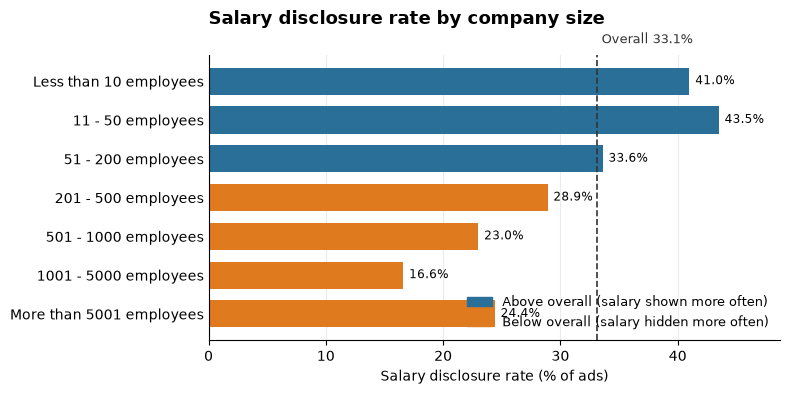

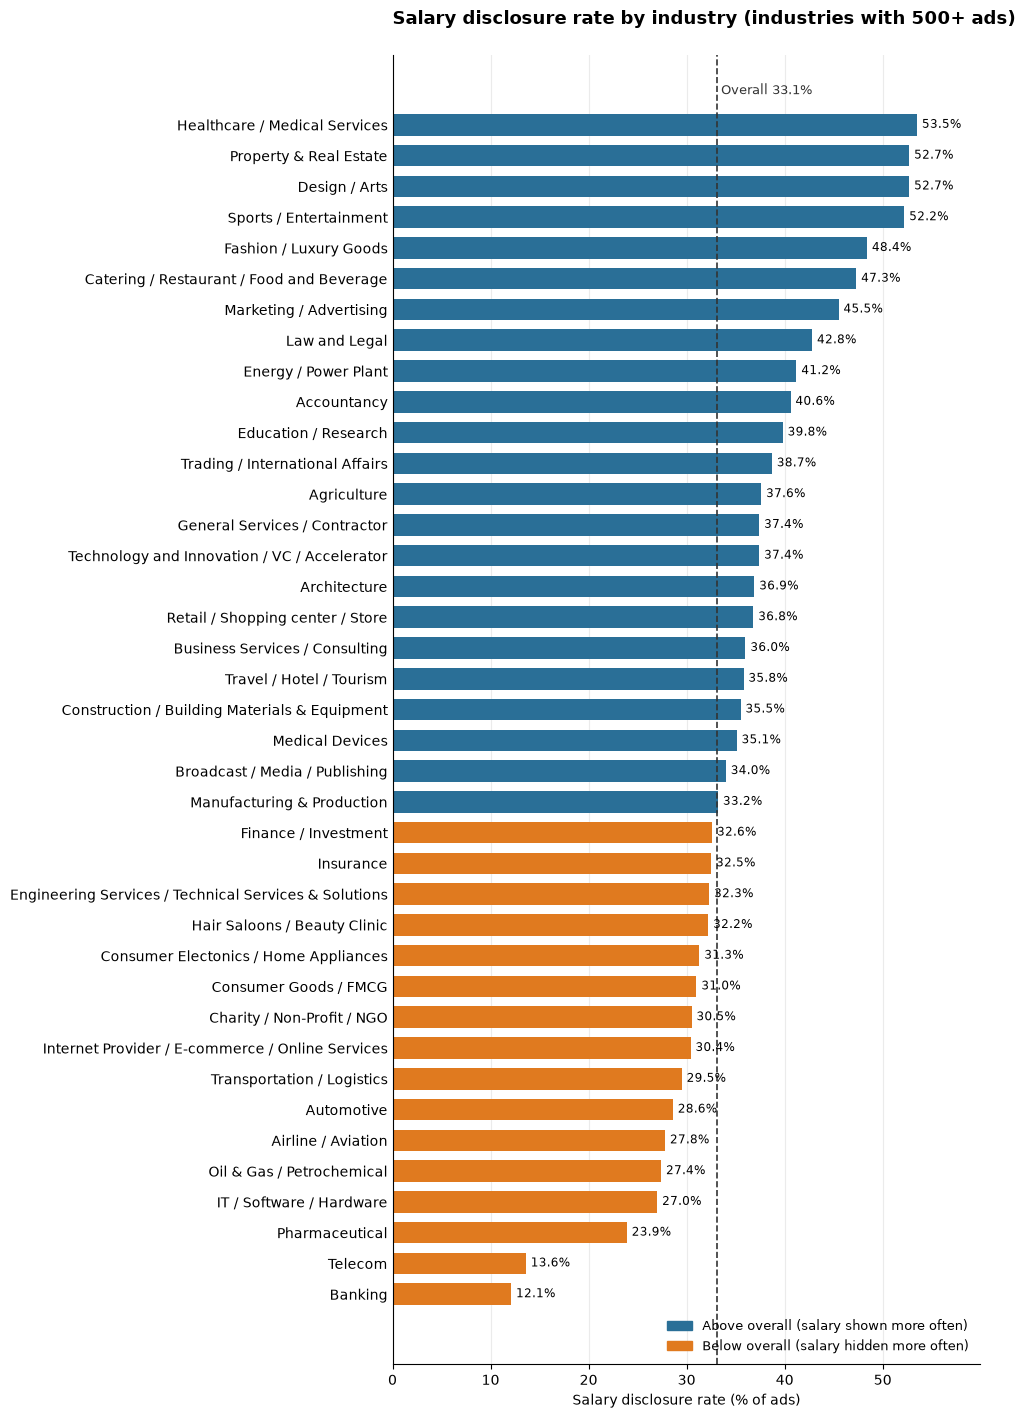

In [61]:
#Visualize the disclosure rate for the most important variables
overall = jobposts_clean["salary_disclosed"].mean() * 100
BLUE, ORANGE = "#2a6f97", "#e07a1f"

def plot_rates(col, title, fname, min_n=500, order=None, width=9):
    t = rates[col].query("ads >= @min_n")
    t = t.loc[order] if order else t.sort_values("rate", ascending=False)

    colors = [BLUE if r >= overall else ORANGE for r in t["rate"]]

    fig, ax = plt.subplots(figsize=(width, 0.32 * len(t) + 1.8))
    bars = ax.barh(t.index, t["rate"], color=colors, height=0.7)
    ax.invert_yaxis()                                   # first row at the top

    ax.axvline(overall, color="#333333", ls="--", lw=1.2)
    ax.text(overall + 0.4, -0.9, f"Overall {overall:.1f}%",
            fontsize=9, color="#333333", va="bottom")

    # value labels
    for bar, r in zip(bars, t["rate"]):
        ax.text(r + 0.5, bar.get_y() + bar.get_height() / 2, f"{r:.1f}%",
                va="center", fontsize=8.5)

    ax.set_xlim(0, t["rate"].max() * 1.12)
    ax.set_xlabel("Salary disclosure rate (% of ads)")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", pad=22)
    ax.xaxis.grid(True, alpha=0.25)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)

    # small legend explaining colors
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=BLUE, label="Above overall (salary shown more often)"),
                       Patch(color=ORANGE, label="Below overall (salary hidden more often)")],
              loc="lower right", frameon=False, fontsize=9)

    plt.tight_layout()
    plt.savefig(f"../outputs/figures/{fname}.png", dpi=200, bbox_inches="tight")
    plt.show()

size_order = ["Less than 10 employees", "11 - 50 employees", "51 - 200 employees",
              "201 - 500 employees", "501 - 1000 employees",
              "1001 - 5000 employees", "More than 5001 employees"]

plot_rates("Company_SizeEn", "Salary disclosure rate by company size",
           "disclosure_by_company_size", order=size_order, width=8)

plot_rates("Jobpost_IndustryEn", "Salary disclosure rate by industry (industries with 500+ ads)",
           "disclosure_by_industry", width=10)

#### Disclosure rate charts 

**Company size:** the larger the company, the less often it shows a salary. Disclosure falls from 43.5% (11-50 employees) to 16.6% (1001-5000). Companies with 200 or fewer employees are above the overall rate (33.1%), and those with more than 200 are below it.

**Industry:** banking (12.1%) and telecom (13.6%) show salaries least often, while healthcare (53.5%), real estate and design (both 52.7%) show them most often. Of the 40 industries with 500+ ads, most sit within a few points of the overall rate, so the big gaps are at the two ends.

These are raw rates. The adjusted effects are in the logistic regression above.

## final Conclusion: Missing Values and Salary-Disclosure Bias

### Executive summary
We checked every column for missing data and studied one question in depth: **which ads show their salary, and which hide it?** Only about one third of ads (120,808 of 364,838, or 33.1%) show a salary. The other two thirds hide it completely, with no partial cases. This hiding is **not random**. It depends mainly on company size, then on job category and industry. Large companies, banks, telecom firms and office or tech roles hide salaries most often, while small companies and service jobs show them most often. This means every salary result in this project describes only the ads that show their salary, not the whole job market. The groups with too little salary data to analyze are tiny and hold less than 0.1% of the shown salaries.

### Key findings

**1. Missing values**
- Seventeen columns have missing values. The most missing are disability support (95.1%), secondary job categories (77.7%), salary (66.9%), language skills (64.5%), academic fields (52.9%) and software skills (46.1%).
- Most of these are "not applicable" or "optional" (the job doesn't need it, or the employer chose not to fill it), not errors. We did not fill or delete anything.
- Hidden missing values were almost absent: only the working-hours text had 204 empty-looking entries, which we converted to missing.

**2. Salary values**
- The "can be shown" flag and the salary values agree perfectly. If the flag is False, both min and max are empty. If True, both exist. So `salary_disclosed` is simply this flag.
- Among the 120,808 ads with a salary, the typical range is 10 to 12 million Toman per month (median min 10, median max 12). A few very high salaries (up to 100) pull the averages up.
- Salaries look like they come from ready-made ranges (12-15, 8-10, 10-12, 15-20, 6-8), and every ad shows a range, never a single number. No ad has min higher than max.

**3. Is salary hiding random?**

**No. Whether an ad shows its salary depends on who posts it.**

- **Three factors matter most:** company size, job category and industry. Their links to salary hiding are moderate (Cramér's V of 0.188, 0.173 and 0.141). Company age, ownership type, employment type and province matter much less (V between 0.054 and 0.090).
- **Company size is the clearest pattern.** The bigger the company, the less often it shows a salary. Small companies (11-50 employees) show it in 43.5% of their ads. For companies with 1001-5000 employees, this drops to 16.6%.
- **Industry:** Banking (12.1%) and telecom (13.6%) show salaries least often. Healthcare (53.5%), real estate and design (both 52.7%) show them most often.
- **The pattern holds when we compare like with like.** In the regression model, a company with 1001-5000 employees has about 3.4 times the odds of hiding its salary compared with a company of 11-50 employees. This is after taking industry, job category and location into account. So company size is not just a side effect of the other factors.
- **The model is only a partial explanation.** Its AUC is 0.661, a modest score. The variables are really linked to salary hiding, but they cannot predict it well. Things we cannot see in the data, such as a company's own pay policy, probably play a role too.

*These are associations, not causes. We can say large companies hide salaries more often, not that being large makes them do it.*

**4. Groups with almost no salary data**

We marked a group as **weak** if it has fewer than 30 ads with a shown salary, because averages are not reliable with so little data. Groups with 30-99 shown salaries are marked **low** and should be used with caution.

- **Weak groups:** 9 of the 77 job categories (for example locksmith, shoemaker, carpet weaver, baker and butcher). No province, industry or company-size group is weak.
- **They are almost irrelevant for the totals.** These 9 categories hold only 268 ads (0.07% of all ads) and 105 shown salaries (0.09% of all shown salaries). Leaving them out loses almost nothing.
- **Low groups:** 10 more job categories (such as tour guide, tailor and barber) and 2 industries (Shipping and Translation) have 30-99 shown salaries. Results for them are tentative.
- **Weak does not mean "hides salaries".** Weak groups are weak because they are tiny. Banking and telecom have the lowest disclosure rates, but they still have 478 and 575 shown salaries, which is enough to analyze. Their results are biased, but they are not too small to use.

### Reusable bias warning (for the report and the presentation)
> Only 33% of job ads in this dataset show a salary, and the ads that hide it are not a random sample. Large companies, banks, telecom firms and office or tech roles hide salaries more often, while small companies and service jobs show them more often. All salary results in this report therefore describe the ads that show their salary, not the whole job market, and pay in large companies and banking is likely under-represented.

### Business takeaways

- **For JobVision:** the sectors with the least salary information (banking, telecom, large companies with 1000+ employees) are the biggest opportunity. A salary-transparency package or an enterprise plan for these clients could raise the share of ads with a salary and make the platform's salary data more useful. Small companies (under 50 employees) already show salaries most often, so they need little convincing.
- **For employers:** if a company shows a salary while similar large employers hide theirs, it stands out. Smaller companies already do this.
- **For job seekers:** salary information is hardest to find at large companies, banks and telecom firms, and in research, data science and product roles. In these areas, ask for the salary early and don't treat the missing number as a sign of low pay. Our data can't tell us what these salaries are.
- **For policymakers:** salary statistics built from job ads under-represent big employers and some white-collar sectors. They should not be read as the whole labor market.

### Limitations and rules for later issues
1. **Never describe the whole market with salary data.** Every salary result should carry the bias warning above or a short version of it.
2. **Do not report averages, growth or rankings for weak groups.** Mark "low" groups as tentative.The list is in `outputs/tables/weak_groups.csv`.
3. **Do not impute missing salaries.** Hiding is informative, so we keep it as a pattern.
4. **Associations, not causes.** We can say hiding is linked to company size, not that size causes it.
5. **Offered ranges, not real pay.** Salaries are ranges chosen by employers (millions of Toman per month, verified), and they come in a limited set of values.
6. **Ads, not companies.** There is no company ID, so one large employer posting many ads counts many times in every rate above.
7. **Missing categories were kept as "Unknown"** (for example, ownership at 24% of ads), not dropped.